```{contents}
:local:
:depth: 2
```

# 3.1 Optimization without Equations

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 6, Lesson 1: *Intro to Data-Driven Optimization*
- Module 6, Lesson 2: *Types of Data-Driven Optimization*
- Module 6, Lesson 3: *Optimality in Data-Driven Optimization*
- Module 6, Lesson 5: *Model-Based Methods*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- State the black-box optimization problem and explain how it differs from the equation-based problems of Topics 1.1–2.6.
- Name the sources of black-box data (experiments, simulations, first-principles codes) and recognize when a black-box method is the wrong choice.
- Classify a data-driven method as direct-search or model-based, and as local or global.
- Explain what optimality can and cannot mean when no derivatives are available.
- Fit a simple surrogate (a quadratic) to samples of a black box and explain why its minimum can sit in the wrong place.
:::

In Topics 1.1–2.6 the optimizer always had access to the equations, so it could compute a gradient, check the KKT conditions, build a convex relaxation, and prove that an answer was optimal. In this part we will remove this access. The objective (and sometimes the constraints) can only be *evaluated*: we choose an input, the system is run, and the output is a single number. An algorithm must learn everything about the problem from these numbers.

This is still the same minimization problem, $\min_x f(x)$ subject to constraints, as in the rest of the book, and the ideas of Topics 1.1–2.6 (feasibility, local versus global optima, bounds and gaps) are all still valid. The difference is in the knowledge available to an algorithm, and therefore in the promises it can make about the answer.

## When the equations are missing

A **black-box optimization problem** is an optimization problem where the objective, and possibly some or all of the constraints, are not available in closed form. We can evaluate them at any chosen point, but we cannot see the formulas, which means that we have no derivatives and no structure to exploit. In standard form,

$$
\begin{aligned}
\min_{x} \quad & f(x) \\
\text{s.t.} \quad & g_j(x) \le 0, \quad j = 1, \ldots, m \\
& x^L \le x \le x^U
\end{aligned}
$$

where $f$ and some of the $g_j$ are now known only through evaluations. The bounds $x^L \le x \le x^U$ are almost always known, since we have to tell the black box what range of inputs is allowed. Several names are used for this setting in the literature: **derivative-free optimization**, **black-box optimization**, **simulation optimization**, and, in this course, **data-driven optimization**. These terms overlap almost completely, so we will use \"black box\" for the function and \"data-driven\" or \"derivative-free\" for the methods.

What is the source of the evaluations? In practice there are three common sources. The first source is **experiments**, such as a pilot plant, a reactor in the lab, or historical operating data, where each data point costs time and money. The second is **computer simulations** (e.g. a process simulator, a computational fluid dynamics model, or a molecular simulation), where each evaluation may take seconds or hours. The third is **first-principles models that are too complicated to hand to an optimizer**. In this case the equations exist but are buried inside a code with iterative solvers, tables and switches, which means that in practice we can only run the code. If some of the equations are known and usable while others can only be evaluated, the problem is often called **grey-box**. Note that if a system is described by an accurate explicit model that a solver can use, we should use that model, since a derivative-based solver with the equations will almost always beat a derivative-free method that ignores the equations.

Optimization without derivatives is an old field (Rios and Sahinidis 2013 review the field and compare the software). The first methods date to the 1960s, a time when derivatives computed from noisy experimental or numerical data could not be trusted because they were too inaccurate. There has been renewed interest for two reasons. First, simulation has become cheap enough to call thousands of times. Second, modern engineering problems chain models across scales, from molecules to plants to supply chains, and no single equation-based formulation can cover the whole system.

The lectures for this module introduce case studies that show the range of applications. In the first, an oilfield operator decides how much water to inject into each well, month by month over five years, to maximize the net present value of the field under a limit on water use. The response of the reservoir comes from a reservoir simulator that can only be queried by the optimizer. In the second, a carbon dioxide capture supply chain is designed: the goal is to decide where to build capture plants and which capture technology (adsorption, membranes, absorption) to use in order to minimize the total cost of capture, transport and storage, and the performance of each technology is computed by a detailed ASPEN process model. A third case study, from an earlier version of this lecture than the recorded video, designs a pharmaceutical tablet plant through a flowsheet of powder-processing unit models, with the goal of minimizing the daily production cost while meeting demand and the tablet specifications. These are the kinds of systems that motivate these methods, but they will not be used as examples in this book. Instead we will keep the electrolyzer plant from the first two modules (Topics 1.1–2.6), since we already know the answers for this plant and can check every method against these known answers.

One more naming issue needs to be clarified at this point. In parts of the literature, \"data-driven optimization\" means something else: optimization *under uncertainty*, where data are used to build the uncertainty sets or scenarios of a robust or stochastic program. That is the subject of the bonus topics on uncertainty, and {doc}`../5-uncertainty/Topic5.1-Stochastic_Programming` sorts out the related terms \"stochastic methods\" and \"stochastic programming\". In Topics 3.1–4.4, \"data-driven\" means that input–output data stand in for missing equations.

:::{exercise}
:label: ex-t31-sources

For each of the following, decide whether a black-box method is appropriate, and if so, which of the three data sources it uses: (a) choosing the reflux ratio of a distillation column modeled in a commercial flowsheet simulator; (b) choosing the loads of the three electrolyzer stacks when the power curves $P_i(x)$ are given as formulas; (c) choosing the temperature and residence time of a new catalytic reaction using bench-scale runs. For the case where a black-box method is the wrong choice, say what you would use instead.
:::

## The electrolyzer as a black box

We will use the same electrolyzer fleet as before, but the solver is only allowed to query the fleet as a black box. The model is unchanged: the stylized S-curve power curve $P_i(x) = x + a_i\,x/(x+\epsilon) + r_i x^2$ of {doc}`../2-nonlinear_mixed_integer/Topic2.6-Non-convex_Problems_and_Bounding`, in per-unit (load $x = 1$ is 200 kg H₂/h; power 1 is the 6.53 MW ideal full-load power). The difference is in the rules of the game: a method in this part may call the function and read the number that it returns, but it may not look inside the function.

This restriction is more than a classroom device. The power curve of a real stack is not an explicit formula in the load. A detailed alkaline electrolyzer model gives the cell voltage and the Faraday efficiency as functions of the current, so finding the power that delivers a given hydrogen output $x$ requires a root-find for the current inside every evaluation (Ulleberg 2003; Sánchez et al. 2018; Baumhof et al. 2023). This means that \"a plant model you can only query\" is literally true of the physics represented by our stylized curve.

We will define three black boxes, where each one is a step harder than the previous one, and we will use their names throughout Topics 3.1–3.6.

- **BB1**: two identical type-A stacks share a demand $D = 0.9$ (180 kg/h), with continuous loads and no on/off decisions. Eliminating the demand balance leaves one decision, the first stack's load $x_1 \in [0, 0.9]$, with $x_2 = 0.9 - x_1$. This is the spatial branch-and-bound instance of Topic 2.6, which proved the optimum in 12 nodes.
- **BB2**: stacks A, B and C share $D = 1.2$ (240 kg/h), with continuous loads and no fixed costs or minimum loads. There are two decisions, $(x_A, x_B)$; stack C takes the rest, $x_C = D - x_A - x_B$, and a point where $x_C$ falls outside $[0, 1]$ returns a penalty value of 10.
- **BB3**: the full MINLP of Topic 2.6 as a black box. The same two decisions, but a stack whose load is below the minimum load $x_{\min} = 0.1$ is off (it costs nothing and makes nothing), and a stack that is on pays the on-cost $F = 0.12$ plus its power. A point where C's load is neither zero nor between $x_{\min}$ and 1 is infeasible and returns 10.

The library `_lib/electrolyzer.py` provides all three as functions `el.bb1`, `el.bb2` and `el.bb3`, which each take a vector of decisions and return one number. Since we want to keep track of the cost of a method, we wrap each black box in a small counter that records every evaluation (`Counter`, in `_lib/part3a_tools.py`). In this part the evaluation count is the price of an answer, in the same way that solver time was the price in Topics 2.1–2.6.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib.part3a_tools import Counter

f = Counter(el.bb1)
for x in (0.0, 0.2, 0.45):
    v = f([x])
    print(f"BB1 at x1 = {x:.2f}: f = {v:.4f} per-unit = {el.to_mw(v):.2f} MW")
print(f"evaluations so far: {f.n}")
print(f"BB2 at (0.4, 0.4): {el.bb2([0.4, 0.4]):.4f}")
print(f"BB3 at (0.4, 0.4): {el.bb3([0.4, 0.4]):.4f}")
print(f"BB3 at (0.05, 0.05): {el.bb3([0.05, 0.05]):.1f}")

BB1 at x1 = 0.00: f = 1.5892 per-unit = 10.39 MW
BB1 at x1 = 0.20: f = 1.6850 per-unit = 11.01 MW
BB1 at x1 = 0.45: f = 1.6425 per-unit = 10.73 MW
evaluations so far: 3
BB2 at (0.4, 0.4): 2.2480
BB3 at (0.4, 0.4): 2.6080
BB3 at (0.05, 0.05): 10.0


The last line shows what infeasibility looks like from the outside. At $(0.05, 0.05)$ both A and B are below the minimum load, which means that they are switched off and C would have to carry all 1.2 units of demand, which is more than the capacity of C. The black box does not give any explanation, and the only output is the value 10.

Since we can see the formulas, we can draw the landscape that is hidden from the solver. The figure below shows BB1 over the whole range and BB2 and BB3 over the $(x_A, x_B)$ square. Note that these maps are only drawn to help us judge the methods later, and that a real black box would never be mapped this densely, since the BB2 and BB3 maps cost 40,401 evaluations each.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


BB1: best 1.58921 at x1 = 0.00 (and at 0.90); equal split 1.6425
BB1 hills at x1 = 0.093 and 0.807
BB2 grid best 2.0818 at (xA, xB) = (0.705, 0.000)
BB3 grid best 2.3218 at (xA, xB) = (0.705, 0.000)
BB3 infeasible (grey) on 44% of the square


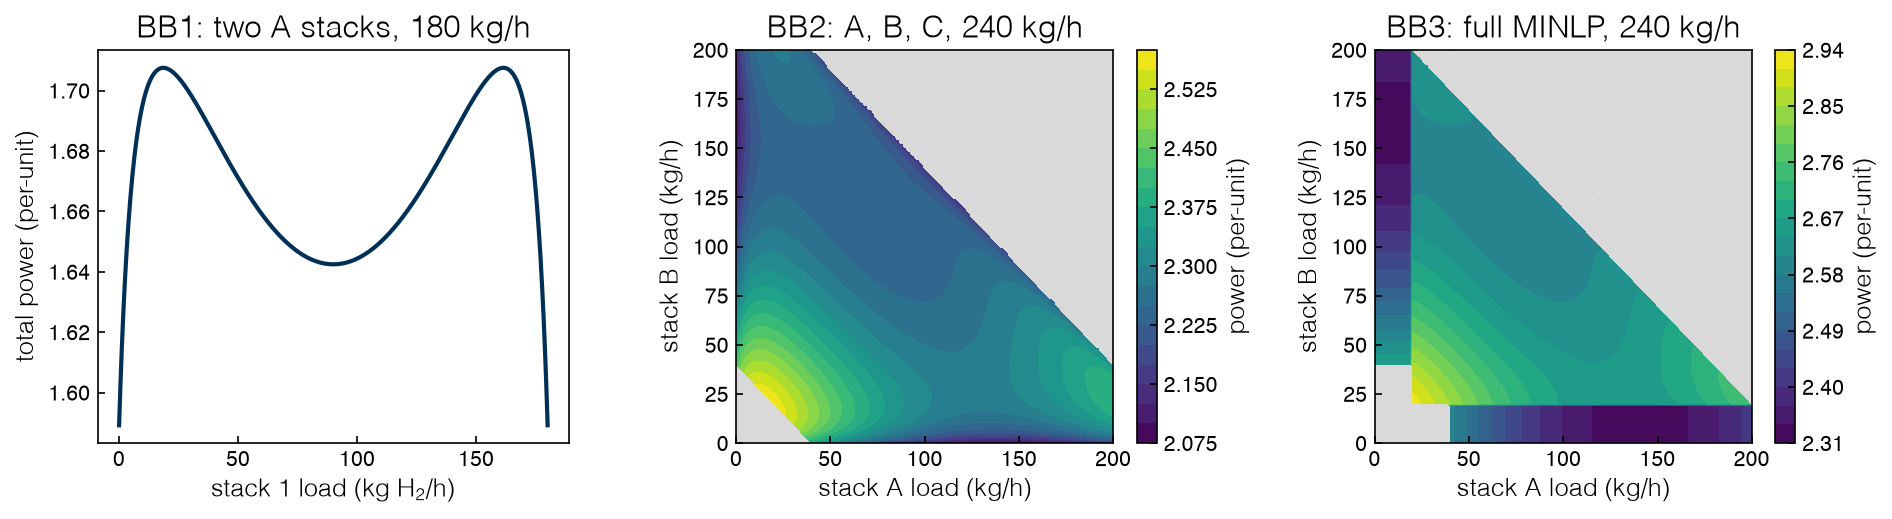

In [2]:
x1 = np.linspace(0, 0.9, 901)
f1 = np.array([el.bb1([v]) for v in x1])
g = np.linspace(0, 1, 201)
XA, XB = np.meshgrid(g, g)
F2 = np.array([[el.bb2([a, b]) for a in g] for b in g])
F3 = np.array([[el.bb3([a, b]) for a in g] for b in g])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(el.to_kg_h(x1), f1)
ax[0].set_xlabel('stack 1 load (kg H$_2$/h)')
ax[0].set_ylabel('total power (per-unit)')
ax[0].set_title('BB1: two A stacks, 180 kg/h')
for a, F, t in ((ax[1], F2, 'BB2: A, B, C, 240 kg/h'), (ax[2], F3, 'BB3: full MINLP, 240 kg/h')):
    a.contourf(el.to_kg_h(XA), el.to_kg_h(XB), (F >= el.PENALTY).astype(float), levels=[0.5, 1.5], colors=['0.85'])
    c = a.contourf(el.to_kg_h(XA), el.to_kg_h(XB), np.ma.masked_where(F >= el.PENALTY, F), levels=20, cmap='viridis')
    a.set_xlabel('stack A load (kg/h)'); a.set_ylabel('stack B load (kg/h)'); a.set_title(t)
    fig.colorbar(c, ax=a, label='power (per-unit)')
plt.tight_layout()

print(f"BB1: best {f1.min():.5f} at x1 = {x1[np.argmin(f1)]:.2f} (and at 0.90); equal split {el.bb1([0.45]):.4f}")
print(f"BB1 hills at x1 = {x1[np.argmax(f1[:200])]:.3f} and {x1[700 + np.argmax(f1[700:])]:.3f}")
k2 = np.unravel_index(np.argmin(F2), F2.shape); k3 = np.unravel_index(np.argmin(F3), F3.shape)
print(f"BB2 grid best {F2.min():.4f} at (xA, xB) = ({g[k2[1]]:.3f}, {g[k2[0]]:.3f})")
print(f"BB3 grid best {F3.min():.4f} at (xA, xB) = ({g[k3[1]]:.3f}, {g[k3[0]]:.3f})")
print(f"BB3 infeasible (grey) on {np.mean(F3 >= el.PENALTY):.0%} of the square")

These pictures preview the difficulties of this part. BB1 has three wells. The global optimum, 1.58921 per-unit (10.39 MW), sits at either edge, with one stack off and the other stack carrying the whole 180 kg/h. The equal split at $x_1 = 0.45$ is a local minimum at 1.6425 (10.73 MW), which is 3.4% worse. The edge wells are narrow, and they are separated from the wide middle well by hills at $x_1 \approx 0.093$ and $0.807$. These are the same wells that trapped the local NLP solver in Topic 2.6.

The best grid point of BB2 lies on the boundary $x_B = 0$ (stack B off). The landscape of BB3 is broken up by the minimum-load switches and by a large grey infeasible region that covers 44% of the square, and the best grid point is the MINLP optimum of Topic 2.6: A + C at loads (0.703, 0.497), with a cost of 2.32181 (the grid point at $x_A = 0.705$ is within $10^{-4}$ of the optimum).

:::{exercise}
:label: ex-t31-counter

Wrap `el.bb3` in a `Counter` and evaluate it on a 21 × 21 grid over the $(x_A, x_B)$ square. How many evaluations did that cost, what is the best grid point, and how far is it from 2.32181? How fine a grid would you need to get within $10^{-3}$, and how many evaluations would that cost? Repeat the estimate for a fleet of 10 stacks (9 free loads).
:::

## Types of data-driven methods

Every data-driven method starts from data, i.e. a set of points where the black box has been evaluated. The points may be chosen at random, by a designed experiment, or one at a time by the algorithm itself, and they may be spread over the whole box or concentrated in a small region. The field can be divided in two based on what a method then does with the data.

**Direct-search** (or sample-driven) methods use the samples directly, which means that they compare function values and decide where to sample next based only on these comparisons, without fitting any model. Compass search and the Nelder–Mead method of Topic 3.2 are examples of direct-search methods.

**Model-based** methods fit an approximate model, called a **surrogate**, to the samples, and then optimize the surrogate with the derivative-based tools of Topics 1.1–2.6. The minimum of the surrogate suggests where to sample next, the new sample improves the surrogate, and the loop continues in this way; these methods are developed in Topics 3.5 and 3.6.

Each family can be used for either a local or a global search. A **local** method only samples a small part of the space at a time, around a current best point, and moves that region in the downhill direction, while a **global** method samples the whole space. If we combine these two distinctions, we get four classes:

| | Local search | Global search |
|---|---|---|
| **Direct-search** | compass (pattern) search, Nelder–Mead (Topic 3.2) | DIRECT, simulated annealing, genetic algorithms, particle swarm (Topic 3.3) |
| **Model-based** | trust-region methods with local linear or quadratic models (Topic 3.6) | global surrogates, efficient global optimization (Topics 3.5 and 3.6) |

The two families trade different costs. Model-based methods give us equations, which means that we also get derivatives and the whole equation-based toolkit. A good surrogate can also predict promising regions, so that fewer samples are needed. However, fitting a model takes effort, every fit introduces approximation error, and a surrogate can be wrong in ways that mislead the optimizer, as we will see in the last section of this topic. Direct-search methods are cheap per step, simple to implement and easy to picture, and make no assumption about the shape of $f$. Since they do not use a model at all, they also cannot be misled by a bad model. On the other hand, they may need many more evaluations, these evaluations are needed at very specific points (which an experiment or a historical data set may not allow), and no reusable knowledge is gained. Which family is best for a given problem will depend on how expensive an evaluation is, how many variables there are, and how noisy the data are.

:::{exercise}
:label: ex-t31-classify

Place each of the following in the table above, and say what information it uses at each step: (a) a grid search followed by a local Nelder–Mead run from the best grid point; (b) fitting a quadratic to the ten most recent samples near the current point and stepping to the quadratic's minimum if it lies within a radius $\Delta$; (c) `scipy.optimize.minimize` with `method='SLSQP'` and finite-difference gradients. Is (c) derivative-free?
:::

## What optimality can mean without derivatives

In Topics 2.1–2.6 optimality had precise meanings: a point is a local optimum if there is no better feasible point in its neighborhood, the KKT conditions identify candidates from the derivatives, and convexity (or a certified lower bound from branch-and-bound) makes a local answer global. In a black-box problem none of this is directly available. We do not know whether the problem is linear, or whether it is convex, and there are no first or second derivatives available for testing. Every theorem from those topics started from some of this knowledge. It is possible that we do not even know which variables matter, or which variables affect the objective and which affect each constraint.

So what can a black-box method guarantee? If nothing is known about $f$, no finite set of samples can rule out a narrow, deep well between two samples. This means that **no method can guarantee the global optimum** without enumerating every possibility or sampling infinitely many points. It turns out that guarantees can only be recovered if we assume something about $f$. Two assumptions carry most of the theory, and each one will be stated precisely in the place where it is used:

- If $f$ is smooth (its gradient exists and does not change too quickly), a local direct-search method can guarantee convergence to a **stationary point**, a point where the gradient is zero, without ever computing the gradient. Topic 3.2 shows why.
- If $f$ cannot change faster than a known rate (it is Lipschitz continuous with a known constant), a global method can compute a valid **lower bound** on $f$ over a region from a single sample, and so prove how far its answer is from the global optimum. Topic 3.3 uses this to close a certified gap on BB1, the way branch-and-bound did in Topic 2.6.

Without such assumptions the practical goal is more modest: to find a point that is as good as possible with the available resources (the evaluation budget, the computing time and the data we can collect), which is often enough in engineering practice. The approach of a method to this goal, and its stopping criterion, depend on four kinds of mechanism that are used in different combinations by the different classes of method: sampling, movement toward better points (descent), subdivision of the space, and bounding of the objective.

**Local convergence mechanisms.** A local direct-search method needs three ingredients: a way to find a descent direction from samples alone, control of the geometry of the sample points so that a descent direction cannot be missed, and a step size that is driven to zero. A local model-based method replaces the first two ingredients with a model. It fits a linear or quadratic surrogate inside a small **trust region**, steps to the minimum of the model, and shrinks the region when the prediction of the model turns out to be poor. Both families stop when the step size (or the trust-region radius) falls below a small threshold.

**Global mechanisms.** A global direct-search method samples the space and divides it into regions, and then keeps sampling and dividing the regions with the most promising values. A global model-based method fits one surrogate over the whole space, optimizes the surrogate, checks the answer by sampling at that point, and then repeats the cycle with a refitted surrogate.

**Stopping and noise.** Without a gradient, a method cannot test $\nabla f = 0$, so it has to stop on a small step size, a small change in $f$, or an exhausted budget. When the evaluations are noisy, comparisons between nearby points become random once the step is so small that the true change in $f$ is below the noise, so noise sets a floor on the step-size criterion; we return to noisy black boxes in the noisy-black-box section of {doc}`../5-uncertainty/Topic5.2-Robust_Optimization`. In one respect data-driven methods can cope with noise better than derivative-based methods: they never difference nearby noisy values, and sampling over a region tends to smooth out small-scale noise, while a finite-difference gradient of noisy data can point in any direction.

**Challenges.** Although these methods have simpler theory and shorter implementations, the problem itself is harder, since the method has less information. The cost that matters shifts from linear algebra to the number of function evaluations, where each evaluation can take hours. Constraints that depend on the data are still an open research question (Topic 3.4). State-of-the-art methods work well up to tens or a few hundred variables, but we should not expect that their accuracy or speed will match a derivative-based solver that has the equations. Dimension is the main enemy of model-based methods in particular. A full quadratic model in $n$ variables has $(n+1)(n+2)/2$ coefficients, so interpolating one in $n = 100$ variables (the local model needed for a Newton-like rate of convergence) costs 5,151 evaluations per model. Cheaper incomplete models trade accuracy for samples: a linear model needs $n + 1$ points, and a model with gradient and diagonal curvature from central differences needs $2n + 1$, in the same way that quasi-Newton methods approximate the Hessian instead of computing the exact Hessian.

On a smooth black box like BB1 it is possible to estimate the gradient by finite differences and then run a derivative-based local solver on the result. In the cell below we use this approach to run SLSQP from three starting points.

In [3]:
from scipy.optimize import minimize

for x0 in (0.45, 0.30, 0.05):
    f = Counter(el.bb1)
    r = minimize(f, [x0], method='SLSQP', bounds=[(0, 0.9)])
    print(f"start {x0:.2f}: x1 = {r.x[0]:.4f}, f = {r.fun:.5f}, success = {r.success}, evaluations = {f.n}")

start 0.45: x1 = 0.4500, f = 1.64250, success = True, evaluations = 2
start 0.30: x1 = 0.4500, f = 1.64250, success = True, evaluations = 8
start 0.05: x1 = 0.0000, f = 1.58921, success = True, evaluations = 4


If the starting point is the equal split, or $x_1 = 0.3$, SLSQP returns the equal-split well at 1.6425 and reports success, exactly as in Topic 2.6. With a starting point of $x_1 = 0.05$, which is inside the narrow edge well, the solver finds the global optimum. Finite differences turn a smooth black box back into an NLP, at the cost of extra evaluations for every gradient, but the solver is still just as blind to the other wells: a local method, with or without derivatives, will find the well that contains its starting point.

:::{exercise}
:label: ex-t31-multistart

Run SLSQP with finite-difference gradients on BB1 from 30 random starting points in $[0, 0.9]$ (use `np.random.default_rng(0)`). In what fraction of runs does it find 1.58921? Compare that fraction with the widths of the three wells you can read off the BB1 figure. What is the total evaluation count of the 30 runs?
:::

## A first model-based method

:::{admonition} Adapted from the course notebook
:class: note
The quadratic-interpolation construction in this section is adapted from the course notebook `Intro to Derivative-Free Optimization (Module6-7).ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), with the electrolyzer black box BB1 in place of the notebook's test functions.
:::

The simplest model-based idea is to fit a quadratic. Three samples $x_1 < x_2 < x_3$ determine a unique quadratic that passes through all three points, which we can write in the Newton form,

$$
q(x) = a_0 + a_1 (x - x_1) + a_2 (x - x_1)(x - x_2),
$$

with $a_0 = f(x_1)$, $a_1 = [f(x_2) - f(x_1)]/(x_2 - x_1)$, and $a_2 = \big([f(x_3) - f(x_1)]/(x_3 - x_1) - a_1\big)/(x_3 - x_2)$. Since there are three points and three parameters, the interpolant has a closed form. If $a_2 > 0$ the quadratic is convex, with a minimum where $dq/dx = 0$; we take that point as our estimate of the optimum and, in a full method, this is where the next sample would be taken. This is the idea behind Powell's quadratic-interpolation line search. Once it has been fitted, the surrogate is an ordinary equation-based problem: the course notebook passes it to Ipopt through Pyomo, but here a one-dimensional grid is enough. A surrogate is only as good as two things: the quality of the fit, and whether it can be optimized in a reliable way (a convex quadratic can be optimized to the global optimum). On a function that really is bowl-shaped the estimate is very good, and the course notebook lands within about 1.4% of the minimizer of $2x^2 + 16/x$ on $[1, 5]$ when the samples are at 1, 3 and 5.

On BB1 the same method fails. In the cell below we draw $n$ points from a Latin hypercube design (a way of spreading samples evenly over the range, developed in Topic 3.5), fit a quadratic by least squares (for $n = 3$ this is the interpolant above), and report the location of the minimum of the quadratic and the true cost of the black box at that point. The sample points come from a helper, `preview_samples`, so that Topic 3.6 can start its surrogate-based search from exactly the same data.

n =  3: convex, minimum at x1 = 0.247, true f there = 1.6719 (optimum 1.5892); max |error| = 0.109
n =  5: convex, minimum at x1 = 0.578, true f there = 1.6547 (optimum 1.5892); max |error| = 0.152
n =  9: convex, minimum at x1 = 0.000, true f there = 1.5892 (optimum 1.5892); max |error| = 0.104
n = 15: convex, minimum at x1 = 0.118, true f there = 1.7054 (optimum 1.5892); max |error| = 0.092


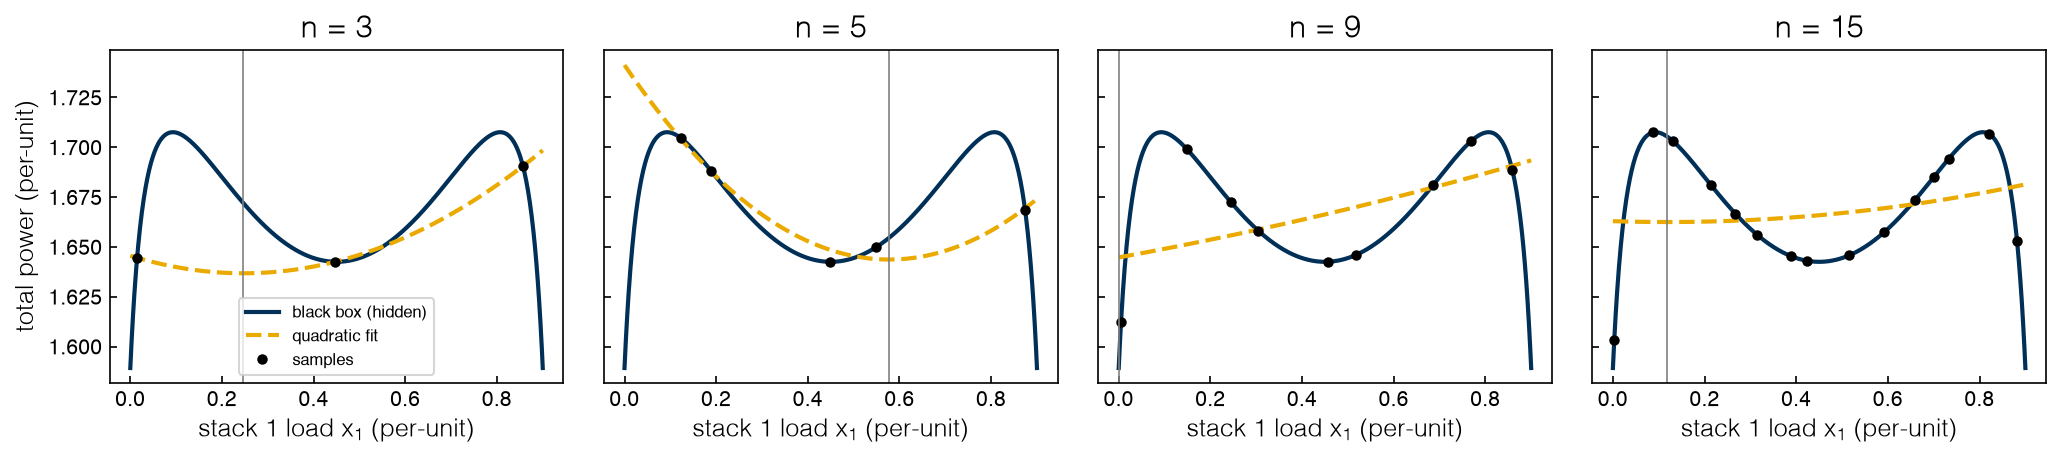

In [4]:
from _lib.part3a_tools import preview_samples

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, n in zip(axes, (3, 5, 9, 15)):
    X = preview_samples(n)                    # Latin hypercube, seed 1, on [0, 0.9]
    y = np.array([el.bb1([v]) for v in X])
    c = np.polyfit(X, y, 2)                   # least-squares quadratic; interpolates when n = 3
    q = np.polyval(c, x1)
    k = np.argmin(q)
    print(f"n = {n:2d}: {'convex' if c[0] > 0 else 'concave'}, minimum at x1 = {x1[k]:.3f}, "
          f"true f there = {f1[k]:.4f} (optimum 1.5892); max |error| = {np.abs(q - f1).max():.3f}")
    ax.plot(x1, f1, label='black box (hidden)')
    ax.plot(x1, q, '--', label='quadratic fit')
    ax.plot(X, y, 'o', color='k', ms=4, label='samples')
    ax.axvline(x1[k], color='0.5', lw=0.8)
    ax.set_title(f'n = {n}')
    ax.set_xlabel('stack 1 load $x_1$ (per-unit)')
axes[0].set_ylabel('total power (per-unit)')
axes[0].legend(fontsize=8)
plt.tight_layout()

Every quadratic is convex, and with three, five or fifteen samples the minimum lands inside the domain, where the true cost is 1.65 to 1.71. This is worse than the equal-split trap. A convex quadratic has a single minimum, so it cannot represent a function with the best points at the two edges and a bowl between them. With nine samples the fit happens to tilt so that its minimum falls on the boundary $x_1 = 0$, which is the true optimum; this is luck in the placement of the samples, not a property of the method. Adding samples does not fix the fit (the maximum error stays between 0.09 and 0.15), because the model has the wrong shape. This is the electrolyzer version of the counterexample from the lecture, $x^2 + 20 \sin(2x)$, which is also completely misrepresented by a quadratic through three points.

The lectures suggest three remedies, and each of them will return later. We can add samples, check the error and refit the model; we can use a more flexible surrogate, such as a Gaussian process (Topic 3.5); or we can fit local models, since a small enough piece of any function, regardless of the number of wells, looks like a bowl or a plane, which is the idea behind trust-region methods.

However, more data and more parameters are not automatically better. The Weierstrass approximation theorem says that a polynomial of high enough order can approximate any continuous function on an interval to any desired accuracy. But with equally spaced samples, high-order interpolating polynomials oscillate wildly near the ends of the interval (Runge's phenomenon, the $1/(1+25x^2)$ example from the lectures), and the minima of these polynomials can land in exactly the wrong place. Both the location of the samples and the kind of model that we fit will decide whether the minimum of the surrogate is meaningful; and the number of samples that we can afford grows quickly with the number of variables. Topic 3.5 takes up both questions, and Topic 3.6 runs a surrogate-based search on BB1 from these same samples.

:::{exercise}
:label: ex-t31-quadratic

Fit the three-point interpolating quadratic of this section to BB1 at the equally spaced points $x_1 = 0$, $0.45$ and $0.9$, computing $a_0$, $a_1$ and $a_2$ from the formulas above. Is the quadratic convex or concave? Where is its minimum over $[0, 0.9]$, and is that the right answer? Now repeat with the points $0.1$, $0.45$ and $0.8$. Explain why the first outcome does not make the method reliable.
:::

:::{exercise}
:label: ex-t31-noise

The course notebook adds a small random error to each of its three samples before fitting the quadratic, to mimic measurement noise. Do the same on BB1 with the three Latin hypercube points from `preview_samples(3)`: add uniform noise between 0 and $\sigma$ to each value for $\sigma$ = 0.001, 0.01 and 0.05 (20 random draws each), refit, and record where the quadratic's minimum lands. Then write the fitted quadratic as a Pyomo model and solve it (Ipopt if it is available, otherwise `scipy.optimize.minimize_scalar` on $[0, 0.9]$). How large must the noise be before the surrogate's minimum moves more than 0.05?
:::

## Summary

- A black-box problem is an ordinary optimization problem whose objective, and possibly constraints, can only be evaluated. Evaluations come from experiments, simulations, or first-principles codes too complex to give to a solver. If usable equations exist, use them.
- The electrolyzer plant becomes three black boxes: BB1 (one load, two A stacks, $D = 0.9$; global optimum 1.58921 at the edges, trap 1.6425 at the equal split), BB2 (two loads, three stacks, $D = 1.2$; optimum on the edge $x_B = 0$), and BB3 (the full MINLP; optimum A + C at 2.32181). A real stack's power curve already needs a root-find inside each evaluation.
- Data-driven methods are direct-search or model-based, and local or global.
- Without assumptions on $f$, no method can guarantee a global optimum. Smoothness gives local direct search a guarantee of stationarity (Topic 3.2); a Lipschitz constant gives a global method a certified bound (Topic 3.3). Noise sets a floor on step-size stopping rules (Topic 5.2).
- A quadratic surrogate of BB1 is convex and puts its minimum between the wells, missing the edge optimum, and more data does not help because the model has the wrong shape. Topics 3.5 and 3.6 develop better surrogates and reuse these samples.

## Additional Reading

- Conn, A. R., Scheinberg, K., and Vicente, L. N. (2009). *Introduction to Derivative-Free Optimization*. SIAM. Chapters 1 and 2 introduce the problem class and the geometry of sample sets.
- Rios, L. M., and Sahinidis, N. V. (2013). Derivative-free optimization: a review of algorithms and comparison of software implementations. *Journal of Global Optimization*, 56, 1247–1293.
- Larson, J., Menickelly, M., and Wild, S. M. (2019). Derivative-free optimization methods. *Acta Numerica*, 28, 287–404.
- Ulleberg, Ø. (2003). Modeling of advanced alkaline electrolyzers: a system simulation approach. *International Journal of Hydrogen Energy*, 28, 21–33.
- Sánchez, M., Amores, E., Rodríguez, L., and Clemente-Jul, C. (2018). Semi-empirical model and experimental validation for the performance evaluation of a 15 kW alkaline water electrolyzer. *International Journal of Hydrogen Energy*, 43, 20332–20345.
- Baumhof, M. T., Raheli, E., Johnsen, A. G., and Kazempour, J. (2023). Optimization of hybrid power plants: when is a detailed electrolyzer model necessary? arXiv:2301.05310. Uses the Ulleberg–Sánchez model inside a plant optimization.
- Forrester, A. I. J., Sóbester, A., and Keane, A. J. (2008). *Engineering Design via Surrogate Modelling: A Practical Guide*. Wiley.